# Notebook 01: KDD Cup 99, the data and the protocol

**Class 03_01.** KDD Cup 99 is the oldest network-intrusion benchmark: 41 features per TCP/IP *connection*
summarised from DARPA 1998 traffic, labelled *normal* or one of 22 attacks in four categories:

| category | what it does | examples |
|:--|:--|:--|
| **dos** | denial of service: floods a service | neptune (SYN flood), smurf, back |
| **probe** | scans hosts and ports | satan, ipsweep, portsweep, nmap |
| **r2l** | remote to local: gets a local account from outside | guess_passwd, warezclient, imap |
| **u2r** | user to root: escalates privileges | buffer_overflow, rootkit, perl |

It is also a famous **bad** data set (Tavallaee et al. 2009; McHugh 2000): most rows are duplicates, the attack
share is unrealistically high, and the traffic is from 1998. We use it *because* its flaws teach the protocol:
deduplicate, set a realistic base rate, threshold on normal data, report per category.

In [1]:
import sys

import numpy as np
import polars as pl
from matplotlib import pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

sys.path.insert(0, ".")
import plots_results as pr

import anomlib as an

plt.rcParams["figure.dpi"] = 100
an.table_config()
raw = an.load_kdd(dedupe=False)
df = an.load_kdd()
print(f"rows: {len(raw):,} -> unique {len(df):,} ({1 - len(df) / len(raw):.1%} duplicates)")
cmp = []
for name, d in [("raw", raw), ("deduplicated", df)]:
    vc = d["category"].value_counts()
    cmp.append({"data": name, **{c: int(vc.get(c, 0)) for c in ["normal", *an.CATEGORIES]},
                "attack share": round(1 - vc["normal"] / len(d), 3)})  # fmt: skip
print(pl.DataFrame(cmp))
pr.dedup(*({c: r[c] for c in ["normal", *an.CATEGORIES]} for r in cmp))  # slide plot: assets/figures/plots/03/dedup.pdf

rows: 494,020 -> unique 145,585 (70.5% duplicates)
┌──────────────┬────────┬────────┬───────┬──────┬─────┬──────────────┐
│ data         ┆ normal ┆ dos    ┆ probe ┆ r2l  ┆ u2r ┆ attack share │
╞══════════════╪════════╪════════╪═══════╪══════╪═════╪══════════════╡
│ raw          ┆ 97277  ┆ 391458 ┆ 4107  ┆ 1126 ┆ 52  ┆ 0.803        │
│ deduplicated ┆ 87831  ┆ 54572  ┆ 2131  ┆ 999  ┆ 52  ┆ 0.397        │
└──────────────┴────────┴────────┴───────┴──────┴─────┴──────────────┘
wrote assets/figures/plots/03/dedup.pdf


**Lesson 1.** In the raw file 80% of the rows are attacks, mostly copies of two floods (smurf, neptune). A detector
evaluated there is rewarded for recognising two DoS patterns. After deduplication normal traffic is the majority,
but the attack share (40%) is still far from any real network.

## The features

Three groups: **basic** (duration, protocol, service, flag, bytes), **content** (failed logins, root shells, file
creations: read from the payload) and **traffic** (counts of connections to the same host or service in the last
2 seconds or 100 connections). Three columns are categorical.

In [2]:
print("categorical:", {c: df[c].nunique() for c in an.CATEGORICAL})
print(df.groupby("category")[["duration", "src_bytes", "dst_bytes", "count", "serror_rate", "num_failed_logins"]]
      .median().round(2))  # fmt: skip

categorical: {'protocol_type': 3, 'service': 66, 'flag': 11}
          duration  src_bytes  dst_bytes  count  serror_rate  \
category                                                       
dos            0.0        0.0        0.0  181.0          1.0   
normal         0.0      240.0      612.0    4.0          0.0   
probe          0.0        0.0        0.0    2.0          0.0   
r2l            0.0      334.0        0.0    1.0          0.0   
u2r           46.0      273.0     2907.0    1.0          0.0   

          num_failed_logins  
category                     
dos                     0.0  
normal                  0.0  
probe                   0.0  
r2l                     0.0  
u2r                     0.0  


Bytes and counts are heavy-tailed (a few connections move megabytes): we take $\log(1+x)$ of them, one-hot encode
the three categorical columns (71 features in total), and z-scale with the mean and standard deviation of the
**normal training rows only**.

## The protocol (novelty detection)

* Normal rows: 60% train, 20% validation, 20% test. **Attacks never appear in training.**
* Test: the normal test rows plus up to 100 attacks per category (u2r has only 52 unique rows: half go to the test,
  half to a *pool* used later as labelled examples). About 1.8% of the test set is attack.
* The threshold is the 99% quantile of the scores on the normal validation set (about 1% false alarms).

In [3]:
sp = an.kdd_split(df, seed=0)
print({k: len(getattr(sp, k)) for k in ["train", "val", "test", "pool"]}, "features:", sp.X("train").shape[1])
print("test attacks per category:", sp.test["category"].value_counts().to_dict())
print(f"attack share of the test set: {sp.y_test.mean():.3%}")

{'train': 52698, 'val': 17566, 'test': 17893, 'pool': 57428} features: 71
test attacks per category: {'normal': 17567, 'dos': 100, 'probe': 100, 'r2l': 100, 'u2r': 26}
attack share of the test set: 1.822%


## ROC or precision-recall?

Two curves summarise a score without choosing a threshold:
* **ROC**: true-positive rate against false-positive rate; AUROC = probability that a random attack scores above a
  random normal row. It ignores the base rate.
* **Precision-recall**: precision against recall; **AUPRC** (average precision) depends on the base rate. A random
  score has AUROC 0.5 but AUPRC equal to the attack share.

Same Mahalanobis detector, same scores, two test sets: the realistic one (1.8% attacks) and a "balanced" one.

┌──────────────────────────┬───────┬───────┬────────┬───────────┬───────┬───────┐
│ test set                 ┆ AUROC ┆ AUPRC ┆ recall ┆ precision ┆ F1    ┆ FPR   │
╞══════════════════════════╪═══════╪═══════╪════════╪═══════════╪═══════╪═══════╡
│ 1.8% attacks             ┆ 0.979 ┆ 0.516 ┆ 0.681  ┆ 0.516     ┆ 0.587 ┆ 0.012 │
│ balanced (pool, 95% dos) ┆ 0.997 ┆ 0.992 ┆ 0.975  ┆ 0.988     ┆ 0.981 ┆ 0.012 │
└──────────────────────────┴───────┴───────┴────────┴───────────┴───────┴───────┘


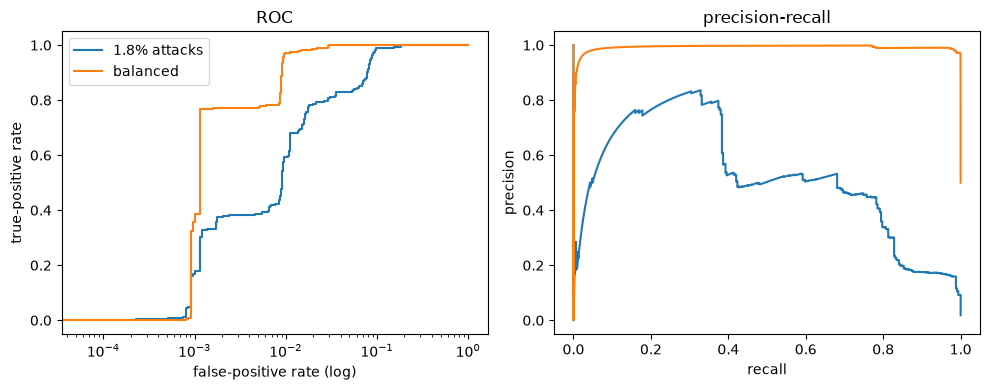

wrote assets/figures/plots/03/roc_vs_pr.pdf


In [4]:
Xtr, Xva, Xte, y = sp.X("train"), sp.X("val"), sp.X("test"), sp.y_test
det = an.Mahalanobis().fit(Xtr)
s_te, s_va = det.score(Xte), det.score(Xva)
Xp = sp.X("pool")
s_bal = np.r_[s_te[y == 0], det.score(Xp[: (y == 0).sum()])]
y_bal = np.r_[np.zeros((y == 0).sum()), np.ones(min(len(Xp), (y == 0).sum()))]
rows = [{"test set": "1.8% attacks", **an.evaluate(s_te, y, s_va)},
        {"test set": "balanced (pool, 95% dos)", **an.evaluate(s_bal, y_bal, s_va)}]  # fmt: skip
print(pl.DataFrame(rows))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for ss, yy, lab in [(s_te, y, "1.8% attacks"), (s_bal, y_bal, "balanced")]:
    fpr, tpr, _ = roc_curve(yy, ss)
    ax[0].plot(fpr, tpr, label=lab)
    p, r, _ = precision_recall_curve(yy, ss)
    ax[1].plot(r, p, label=lab)
ax[0].set(xscale="log", xlabel="false-positive rate (log)", ylabel="true-positive rate", title="ROC")
ax[1].set(xlabel="recall", ylabel="precision", title="precision-recall")
ax[0].legend()
plt.tight_layout()
plt.show()

# slide plot: assets/figures/plots/03/roc_vs_pr.pdf
pr.roc_vs_pr(y, s_te, y_bal, s_bal)

**Lesson 2.** The ROC curve barely changes with the base rate; precision collapses when attacks are rare. Report
AUPRC (and the precision at your threshold) for a detector that will face rare events, and always state the base
rate of the test set.

**Lesson 3 (what to report).** At the 1% validation threshold: recall, precision, F1, the *measured* FPR on the
normal test rows (it should be close to 1%), and the recall **per category**, because one easy category (dos)
can hide a blind spot (r2l).